# Learning Curves — Breast Cancer Classification

## Objectives

- Understand the relationship between training data size and model performance.
- Generate training and validation learning curves.
- Diagnose potential underfitting and overfitting.
- Investigate whether additional training data may improve performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    learning_curve
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

In [2]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (455, 30)
Testing shape: (114, 30)


In [3]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [4]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
train_sizes = np.linspace(
    0.10,
    1.00,
    10
)

train_sizes

array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [6]:
train_sizes_abs, train_scores, validation_scores = learning_curve(
    estimator=pipeline,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=cv_strategy,
    scoring="accuracy",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

In [7]:
print("Training sizes:", train_sizes_abs)

print("\nTraining scores shape:")
print(train_scores.shape)

print("\nValidation scores shape:")
print(validation_scores.shape)

Training sizes: [ 36  72 109 145 182 218 254 291 327 364]

Training scores shape:
(10, 5)

Validation scores shape:
(10, 5)


In [8]:
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

In [9]:
learning_curve_df = pd.DataFrame({
    "Training Samples": train_sizes_abs,
    "Training Mean Accuracy": train_mean,
    "Training Std": train_std,
    "Validation Mean Accuracy": validation_mean,
    "Validation Std": validation_std
})

learning_curve_df

,Training Samples,Training Mean Accuracy,Training Std,Validation Mean Accuracy,Validation Std
0,36,1.000000,0.000000,0.962637,0.005383
1,72,0.994444,0.006804,0.953846,0.014579
2,109,0.990826,0.005802,0.967033,0.012038
3,145,0.991724,0.006757,0.960440,0.011207
4,182,0.992308,0.004396,0.967033,0.006950
5,218,0.988991,0.003670,0.973626,0.011207
6,254,0.988189,0.002490,0.971429,0.008791
7,291,0.988316,0.001683,0.971429,0.011207
8,327,0.988991,0.001498,0.973626,0.011207
9,364,0.989011,0.000000,0.978022,0.009829


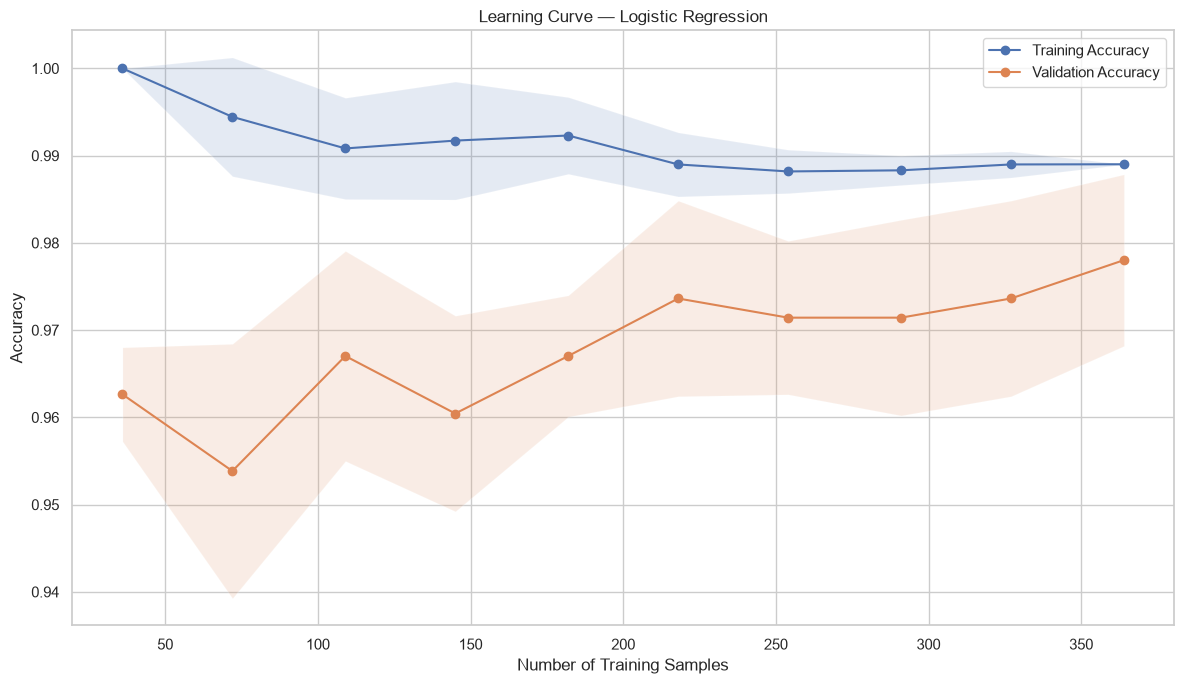

In [10]:
plt.figure(figsize=(12, 7))

plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    train_sizes_abs,
    validation_mean,
    marker="o",
    label="Validation Accuracy"
)

plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes_abs,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.title("Learning Curve — Logistic Regression")
plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")

plt.legend()

plt.tight_layout()
plt.show()